# When to think, what to remember, when to be surprised — what the Connect Four games say

Three experiments on Qwen3-4B playing Connect Four, every move judged by the exact solver (a *blunder* is a move that
changes the game-theoretic value; a position is *critical* when exactly one move keeps the value, *quiet* otherwise: the next section explains the three words with an example). Each section ends
with a verdict: what the games show, what they do not, and how sure we can be (95% Wilson intervals, Fisher tests).

| Experiment | Question | Grid | Modes |
|---|---|---|---|
| A. The gate | Does choosing *which* moves to think on beat thinking on a clock? | `duel_c4_gate.yaml` | `goracle`, `gcrit`, `gself`, `grand28/42/55` vs `e1`, `r4` |
| B. The memory | Is a summary of the reasoning a useful middle ground between keeping and dropping it? | `duel_c4_summary.yaml` | `s1`, `ls1`, `l1`, `e1`, `sr4`, `lsr4`, `r4` |
| C. The surprise | Can the model's own expectation of the opponent's reply tell it when to think? | `duel_c4_surprise.yaml` (prompt `predict`) | `gsurp`, `grand35`, `gcrit`, `e1`, `r4` |

Run from `Code/Benchmark` with the results folder below (the Colab results copied from Drive). Each game has a `.moves.jsonl`
next to its record; `gate_analysis.move_table()` reads them.

## The words used: blunder, critical position, quiet position

All three come from the exact solver, not from a judgement of ours. Connect Four is solved: for any position the solver
knows the result with perfect play from both sides, and it gives every playable column a score from the point of view of
the player to move. Positive means that column wins with perfect play, zero that it draws, negative that it loses. We only
use the sign, the *class* of the move: **win**, **draw** or **loss**. The *value* of a position is the class of its best move.

**Blunder.** A move whose class is worse than the best one available: it turns a won position into a draw or a loss, or a
drawn one into a loss. It is the strictest and simplest definition of a mistake: the result of the game, with perfect
play, is no longer the same after the move.
- A slower win is *not* a blunder (the class is still win), so "blunder" says nothing about style or speed.
- In a position that is already lost every move loses, so no blunder is possible there. This is 30% of the positions the
  model meets; together with the won or drawn positions where every column keeps the value, 37% of the positions cannot be blundered.
- The *blunder rate* of a mode is its blunders divided by all its judged moves. It is counted per move, so it rests on
  hundreds of moves where the score rests on tens of games.

**Critical position.** A position where exactly **one** column keeps the value: play it or the result changes. Every other
column is a blunder. 26% of the positions are critical (85% of them are won positions with a single winning move, 15% drawn
positions with a single drawing move). Two very different situations fall under this word, and section D separates them:
in the first six plies "critical" mostly means "only the centre keeps the win"; later it means a threat to see and block,
or a single winning continuation to find.

**Quiet position.** Every position that is not critical: two or more columns keep the value (or none can lose it, as in a
lost position). A careless move is often still fine. Quiet does not mean safe: a blunder is possible whenever at least
one column changes the value, and the model blunders 18% of its moves on quiet positions against 76% on critical ones.

**An example** (`goracle` against `greedy`, seed 14; the agent plays O and is to move in both positions).

| | Critical (ply 8) | Quiet (ply 10) |
|---|---|---|
| Solver scores, columns 1 to 7 | -3, **+4**, -2, -2, 0, 0, -2 | -2, **+5**, **+5**, **+1**, -2, **+5**, -2 |
| Value of the position | win | win |
| Columns that keep it | 2 only | 2, 3, 4 and 6 |
| The model's answer without thinking | 4: a loss, a **blunder** | 3: a win, fine |
| What it played | 3 after thinking: a loss, a **blunder** | 3, without thinking |

In the critical position the model had a won game and one column to find; it missed it without thinking and again after
4700 tokens of reasoning. Two moves later four columns out of seven still won, and the unthought answer was enough.

Two more words used with these. A move is **thought** when the model reasoned before answering and **fast** when it
answered directly. On every thinking turn the model is also asked for its fast answer first, which is recorded and not
played (the *shadow* fast move): this is how we know whether thinking **repaired** a blunder (fast answer a blunder,
thought move not) or **spoiled** a good answer (the opposite).

In [1]:
import os, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import fisher_exact, mannwhitneyu
from records import load_table
import gate_analysis as ga

RESULTS = "results"
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.precision", 2)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "axes.titlesize": 11, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
                     "legend.fontsize": 8})

games = load_table(RESULTS)
games = games[(games.source == "benchmark-duel") & (games.game == "connect_four") & (games.model == "Qwen/Qwen3-4B")].copy()
games = games[~games.prompt.str.contains("+", regex=False)].copy()  # the board grid (plain+columns, plain+both) is read apart
games["sc"] = games.result.map({"win": 1, "draw": 0.5, "loss": 0})
games["win"] = games.result == "win"
moves = ga.move_table(RESULTS, rebuild=False)          # one row per move of an agent of the model, with the solver's view
moves = moves[~moves.prompt.str.contains("+", regex=False)].copy()
own = moves[(moves.player == "agent") & moves.judged].copy()  # the agent's own moves (the self-play opponent is the same e1 everywhere)
print(f"{len(games)} games, {len(moves)} judged moves of which {len(own)} by the agent")

# --- helpers -------------------------------------------------------------------------------------------------
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; den = 1 + z * z / n; c = (p + z * z / (2 * n)) / den
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (c - h, c + h)

def rate(series):
    s = series.dropna().astype(bool); k, n = int(s.sum()), len(s)
    lo, hi = wilson(k, n); return pd.Series(dict(n=n, k=k, p=k / n if n else np.nan, lo=lo, hi=hi))

def fisher(a, b, label_a, label_b, what):
    "two-sided Fisher test between two boolean series"
    a, b = a.dropna().astype(bool), b.dropna().astype(bool)
    table = [[a.sum(), len(a) - a.sum()], [b.sum(), len(b) - b.sum()]]
    _, p = fisher_exact(table)
    return dict(what=what, a=label_a, rate_a=a.mean(), n_a=len(a), b=label_b, rate_b=b.mean(), n_b=len(b), p=p,
                verdict="different (p<0.05)" if p < 0.05 else "not distinguishable")

def bars(ax, table, column, title, ylabel, colors=None, ylim=(0, 1), fmt="{:.0%}"):
    "bars with 95% intervals from a table with columns p, lo, hi indexed by mode"
    x = np.arange(len(table))
    err = np.vstack([table.p - table.lo, table.hi - table.p])
    ax.bar(x, table.p, yerr=err, capsize=3, color=colors or "#4C78A8", edgecolor="none")
    for xi, (p, n) in enumerate(zip(table.p, table.n)):
        ax.text(xi, min(p + 0.03, 1.02), f"{fmt.format(p)}\nn={int(n)}", ha="center", va="bottom", fontsize=7)
    ax.set_xticks(x); ax.set_xticklabels(table.index, rotation=0)
    ax.set_ylim(*ylim); ax.set_title(title); ax.set_ylabel(ylabel)

FAMILY = {"e1": "#333333", "r4": "#333333", "l1": "#7F7F7F", "lr4": "#7F7F7F", "er4": "#7F7F7F",
          "goracle": "#E45756", "gcrit": "#F58518", "gself": "#54A24B", "gsurp": "#72B7B2",
          "grand28": "#4C78A8", "grand35": "#4C78A8", "grand42": "#4C78A8", "grand55": "#4C78A8",
          "s1": "#B279A2", "ls1": "#B279A2", "sr4": "#B279A2", "lsr4": "#B279A2"}
def palette(modes): return [FAMILY.get(m, "#4C78A8") for m in modes]

1832 games, 20193 judged moves of which 12674 by the agent


## The data

The three grids share the opponents (the one-ply `greedy` bot and `self-e1`, the model itself thinking every move) and the
seeds; A and B use the `plain` and `free` prompts, C the `predict` prompt. The `e1` and `r4` games of A are reused by B.

In [2]:
A_MODES = ["e1", "r4", "goracle", "gcrit", "gself", "grand28", "grand42", "grand55"]
B_MODES = ["e1", "l1", "ls1", "s1", "r4", "lr4", "er4", "lsr4", "sr4"]
C_MODES = ["e1", "r4", "gcrit", "grand35", "gsurp"]
base = games.level.isin(["greedy", "self-e1"]) & games.prompt.isin(["plain", "free"])
A = games[base & games["mode"].isin(A_MODES) & games.seed.between(1, 15)]
B = games[base & games["mode"].isin(B_MODES)]
Cg = games[(games.prompt == "predict") & games["mode"].isin(C_MODES)]
mbase = own.level.isin(["greedy", "self-e1"]) & own.prompt.isin(["plain", "free"])
Am = own[mbase & own.player_mode.isin(A_MODES) & own.seed.between(1, 15)]
Bm = own[mbase & own.player_mode.isin(B_MODES)]
Cm = own[(own.prompt == "predict") & own.player_mode.isin(C_MODES)]
inventory = pd.DataFrame({"A gate": A.groupby("mode").size(), "B memory": B.groupby("mode").size(), "C surprise": Cg.groupby("mode").size()}).fillna(0).astype(int)
inventory.loc["total"] = inventory.sum()
inventory

,A gate,B memory,C surprise
mode,,,
e1,60,100,50
er4,0,12,0
gcrit,60,0,50
goracle,60,0,0
grand28,60,0,0
grand35,0,0,50
grand42,60,0,0
grand55,60,0,0
gself,60,0,0


## A. The gate: which moves to think on

`e1` thinks on every move and `r4` about every fourth; a gate mode thinks only when its gate says so.
`goracle` answers fast first and the solver tells it whether that fast move is a blunder (the ceiling: a gate that knows exactly when thinking could help);
`gcrit` thinks when the solver says the position is critical (no model tokens); `gself` asks the model itself, without thinking, whether the position
needs thought; `grand<p>` thinks at random with probability p%, at the firing rates measured for the three gates (28, 42, 55%), to separate
*how often* from *which moves*.

In [3]:
def game_table(frame, level):
    g = frame[frame.level == level]
    rows = {}
    for mode, part in g.groupby("mode"):
        r = rate(part.win); rows[mode] = dict(games=len(part), score=part.sc.mean(), win=r.p, lo=r.lo, hi=r.hi,
                                              think_rate=part.think_rate.mean(), blunders_per_game=part.blunders.mean(),
                                              ktokens=part.tokens_generated.mean() / 1000, illegal_per_game=part.illegal.mean())
    return pd.DataFrame(rows).T
order_A = ["r4", "grand28", "gcrit", "grand42", "goracle", "gself", "grand55", "e1"]  # by thinking rate, roughly
print("Against the model itself (self-e1):"); display(game_table(A, "self-e1").loc[order_A].round(2))
print("Against the greedy bot:"); display(game_table(A, "greedy").loc[order_A].round(2))

Against the model itself (self-e1):


,games,score,win,lo,hi,think_rate,blunders_per_game,ktokens,illegal_per_game
r4,30.0,0.27,0.27,0.14,0.44,0.17,2.81,4.49,0.07
grand28,30.0,0.33,0.33,0.19,0.51,0.25,2.20,6.20,0.10
gcrit,30.0,0.43,0.43,0.27,0.61,0.35,2.37,8.14,0.23
grand42,30.0,0.53,0.53,0.36,0.70,0.41,2.03,9.74,0.17
goracle,30.0,0.63,0.63,0.46,0.78,0.46,1.33,10.57,0.03
gself,30.0,0.30,0.30,0.17,0.48,0.36,3.33,16.11,0.03
grand55,30.0,0.40,0.40,0.25,0.58,0.55,2.00,15.09,0.07
e1,30.0,0.57,0.57,0.39,0.73,0.86,2.23,27.37,0.07


Against the greedy bot:


,games,score,win,lo,hi,think_rate,blunders_per_game,ktokens,illegal_per_game
r4,30.0,0.00,0.00,-0.00,0.11,0.16,2.67,5.22,0.33
grand28,30.0,0.03,0.03,0.01,0.17,0.24,2.77,6.39,0.23
gcrit,30.0,0.10,0.07,0.02,0.21,0.27,2.43,7.92,0.73
grand42,30.0,0.13,0.13,0.05,0.30,0.42,2.90,15.31,0.07
goracle,30.0,0.03,0.03,0.01,0.17,0.44,2.13,13.84,0.20
gself,30.0,0.00,0.00,-0.00,0.11,0.60,2.87,26.47,0.00
grand55,30.0,0.05,0.03,0.01,0.17,0.55,2.93,20.15,0.37
e1,30.0,0.03,0.03,0.01,0.17,0.86,3.07,32.53,0.17


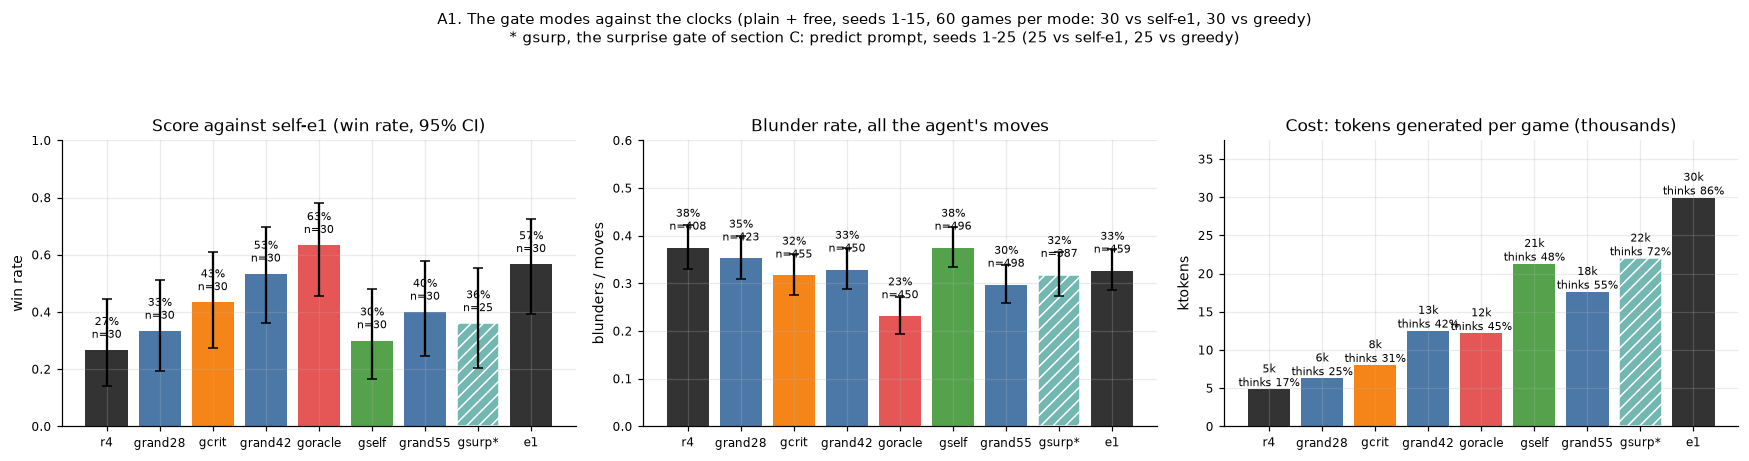

gsurp* against e1 (plain + free, seeds 1-15):


,what,a,rate_a,n_a,b,rate_b,n_b,p,verdict
0,win rate vs self-e1,gsurp,0.36,25,e1,0.57,30,0.18,not distinguishable
1,blunder rate,gsurp,0.32,387,e1,0.33,459,0.82,not distinguishable


In [4]:
def move_rates(frame, by="player_mode", order=None):
    out = frame.groupby(by).blunder.apply(rate).unstack()
    return out.loc[[m for m in order if m in out.index]] if order else out

# the surprise gate next to the others. It needs the predict prompt (the model states the reply it expects), so it is
# not the same prompt as the other bars (plain + free): gsurp* is hatched, and it has 25 seeds instead of 15.
S = games[(games.prompt == "predict") & (games["mode"] == "gsurp") & games.level.isin(["self-e1", "greedy"])]
Sm = own[(own.prompt == "predict") & (own.player_mode == "gsurp") & own.level.isin(["self-e1", "greedy"])]
A1, A1m = pd.concat([A, S]), pd.concat([Am, Sm])
order_A1 = ["r4", "grand28", "gcrit", "grand42", "goracle", "gself", "grand55", "gsurp", "e1"]  # by thinking rate, roughly
labels_A1 = [m + "*" if m == "gsurp" else m for m in order_A1]

def mark(ax):  # hatch the bar of gsurp and star its label
    ax.patches[order_A1.index("gsurp")].set_hatch("///"); ax.patches[order_A1.index("gsurp")].set_edgecolor("white")
    ax.set_xticklabels(labels_A1)

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
t = A1[A1.level == "self-e1"].groupby("mode").win.apply(rate).unstack().loc[order_A1]
bars(axes[0], t, "p", "Score against self-e1 (win rate, 95% CI)", "win rate", palette(order_A1)); mark(axes[0])
t = move_rates(A1m, order=order_A1)
bars(axes[1], t, "p", "Blunder rate, all the agent's moves", "blunders / moves", palette(order_A1), ylim=(0, 0.6)); mark(axes[1])
g = A1.groupby("mode").agg(ktok=("tokens_generated", lambda s: s.mean() / 1000), think=("think_rate", "mean")).loc[order_A1]
axes[2].bar(np.arange(len(g)), g.ktok, color=palette(order_A1)); axes[2].set_xticks(np.arange(len(g))); mark(axes[2])
for i, (k, th) in enumerate(zip(g.ktok, g.think)): axes[2].text(i, k + 0.4, f"{k:.0f}k\nthinks {th:.0%}", ha="center", fontsize=7)
axes[2].set_title("Cost: tokens generated per game (thousands)"); axes[2].set_ylabel("ktokens"); axes[2].set_ylim(0, g.ktok.max() * 1.25)
fig.suptitle("A1. The gate modes against the clocks (plain + free, seeds 1-15, 60 games per mode: 30 vs self-e1, 30 vs greedy)\n"
             "* gsurp, the surprise gate of section C: predict prompt, seeds 1-25 (25 vs self-e1, 25 vs greedy)", y=1.09, fontsize=10)
plt.tight_layout(); plt.show()
print("gsurp* against e1 (plain + free, seeds 1-15):")
display(pd.DataFrame([fisher(S[S.level == "self-e1"].win, A[(A["mode"] == "e1") & (A.level == "self-e1")].win, "gsurp", "e1", "win rate vs self-e1"),
                      fisher(Sm.blunder, Am[Am.player_mode == "e1"].blunder, "gsurp", "e1", "blunder rate")]).round(3))


**Reading A1.** Against itself, `goracle` is the best mode on every count: the highest score, the lowest blunder rate, at 40% of `e1`'s tokens.
But the random gate at the same firing rate (`grand42`) is not distinguishable from it on score, only on blunders. `gself` fires more often
than `goracle` and plays like `r4`. Against the greedy bot every mode loses almost every game: a one-ply lookahead is enough against Qwen3-4B.
`gsurp*` (the surprise gate, section C) is drawn here for comparison only: it plays with the predict prompt and on 25 seeds, so its bar is not
a like-for-like comparison with the others. It thinks on about three moves out of four, pays most of `e1`'s tokens, and does not blunder less than `e1`.

In [5]:
tests = pd.DataFrame([
    fisher(Am[Am.player_mode == "goracle"].blunder, Am[Am.player_mode == "e1"].blunder, "goracle", "e1", "blunder rate"),
    fisher(Am[Am.player_mode == "goracle"].blunder, Am[Am.player_mode == "grand42"].blunder, "goracle", "grand42", "blunder rate (same firing rate)"),
    fisher(A[(A.level == "self-e1") & (A["mode"] == "goracle")].win, A[(A.level == "self-e1") & (A["mode"] == "grand42")].win, "goracle", "grand42", "win vs self-e1"),
    fisher(A[(A.level == "self-e1") & (A["mode"] == "goracle")].win, A[(A.level == "self-e1") & (A["mode"] == "e1")].win, "goracle", "e1", "win vs self-e1"),
    fisher(Am[Am.player_mode == "gself"].blunder, Am[Am.player_mode == "grand55"].blunder, "gself", "grand55", "blunder rate (same firing rate)"),
    fisher(Am[Am.player_mode == "gcrit"].blunder, Am[Am.player_mode == "grand28"].blunder, "gcrit", "grand28", "blunder rate (same firing rate)"),
    fisher(A[(A.level == "self-e1") & (A["mode"] == "gcrit")].win, A[(A.level == "self-e1") & (A["mode"] == "grand28")].win, "gcrit", "grand28", "win vs self-e1"),
    fisher(Am[Am.player_mode == "e1"].blunder, Am[Am.player_mode == "r4"].blunder, "e1", "r4", "blunder rate"),
])
tests.round(3)

,what,a,rate_a,n_a,b,rate_b,n_b,p,verdict
0,blunder rate,goracle,0.23,450,e1,0.33,459,1.00e-03,different (p<0.05)
1,blunder rate (same firing rate),goracle,0.23,450,grand42,0.33,450,1.00e-03,different (p<0.05)
2,win vs self-e1,goracle,0.63,30,grand42,0.53,30,6.01e-01,not distinguishable
3,win vs self-e1,goracle,0.63,30,e1,0.57,30,7.92e-01,not distinguishable
4,blunder rate (same firing rate),gself,0.38,496,grand55,0.30,498,1.10e-02,different (p<0.05)
5,blunder rate (same firing rate),gcrit,0.32,455,grand28,0.35,423,2.83e-01,not distinguishable
6,win vs self-e1,gcrit,0.43,30,grand28,0.33,30,5.96e-01,not distinguishable
7,blunder rate,e1,0.33,459,r4,0.38,408,1.54e-01,not distinguishable


### Where the blunders are

A quarter of the positions are critical. The next figure splits every mode's moves by the position (critical / quiet) and by whether the
move was thought.

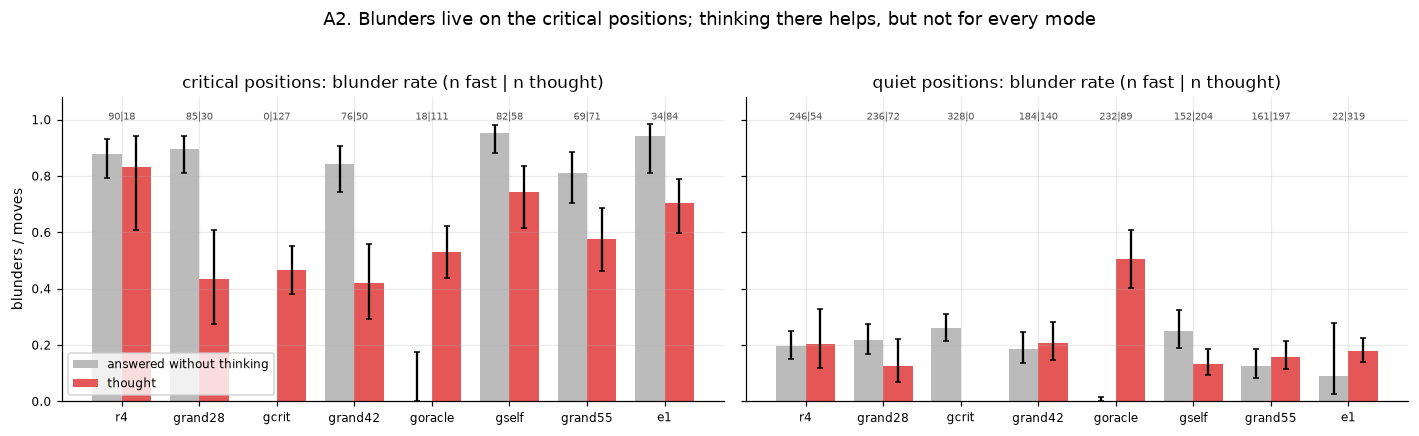

,what,a,rate_a,n_a,b,rate_b,n_b,p,verdict
0,blunder on critical moves that were thought,gcrit,0.47,127,e1,0.7,84,1.00e-03,different (p<0.05)
1,blunder on critical moves that were thought,grand42,0.42,50,e1,0.7,84,2.00e-03,different (p<0.05)


In [6]:
Am2 = Am.copy(); Am2["kind"] = np.where(Am2.critical, "critical", "quiet")
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, kind in zip(axes, ["critical", "quiet"]):
    part = Am2[Am2.kind == kind]
    th = part[part.think].groupby("player_mode").blunder.apply(rate).unstack().reindex(order_A)
    fa = part[~part.think].groupby("player_mode").blunder.apply(rate).unstack().reindex(order_A)
    x = np.arange(len(order_A)); w = 0.38
    ax.bar(x - w/2, fa.p, w, yerr=np.vstack([fa.p - fa.lo, fa.hi - fa.p]).clip(0), capsize=2, color="#BBBBBB", label="answered without thinking")
    ax.bar(x + w/2, th.p, w, yerr=np.vstack([th.p - th.lo, th.hi - th.p]).clip(0), capsize=2, color="#E45756", label="thought")
    for xi, (a, b) in enumerate(zip(fa.n, th.n)): ax.text(xi, 1.0, f"{int(a) if a==a else 0}|{int(b) if b==b else 0}", ha="center", fontsize=6.5, color="#555")
    ax.set_xticks(x); ax.set_xticklabels(order_A); ax.set_ylim(0, 1.08); ax.set_title(f"{kind} positions: blunder rate (n fast | n thought)")
axes[0].set_ylabel("blunders / moves"); axes[0].legend(loc="lower left")
fig.suptitle("A2. Blunders live on the critical positions; thinking there helps, but not for every mode", y=1.03)
plt.tight_layout(); plt.show()
crit_th = Am2[(Am2.kind == "critical") & Am2.think]
pd.DataFrame([fisher(crit_th[crit_th.player_mode == "gcrit"].blunder, crit_th[crit_th.player_mode == "e1"].blunder, "gcrit", "e1", "blunder on critical moves that were thought"),
              fisher(crit_th[crit_th.player_mode == "grand42"].blunder, crit_th[crit_th.player_mode == "e1"].blunder, "grand42", "e1", "blunder on critical moves that were thought")]).round(3)

**Reading A2.** On quiet positions the fast answer is fine 75-90% of the time in every mode: the thinking that `e1` spends there (93% of its
quiet moves) changes little. On critical positions a fast answer is a blunder 80-95% of the time, so a gate that finds them is the whole game.
The thought bars also differ a lot between modes (`gcrit`, `grand28`, `grand42` about 45%, `e1` 70%): section D shows this is a selection effect
of *when* in the game the critical positions come, not a difference in the quality of the reasoning.

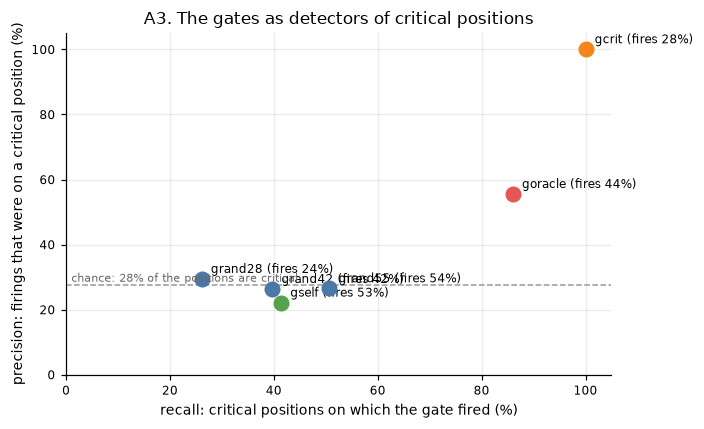

,fired_pct,critical_precision,critical_recall,fast_blunder_precision
player_mode,,,,
gcrit,27.9,100.0,100.0,82.5
goracle,44.4,55.5,86.0,100.0
gself,52.8,22.1,41.4,30.2
grand28,24.1,29.4,26.1,36.6
grand42,42.2,26.3,39.7,37.1
grand55,53.8,26.5,50.7,37.2


In [7]:
# the gates against the solver: precision / recall for "the position is critical", with the chance level (the base rate)
q = ga.gate_quality(Am).reindex(["gcrit", "goracle", "gself", "grand28", "grand42", "grand55"])
basecrit = Am.critical.mean() * 100
fig, ax = plt.subplots(figsize=(6.5, 4))
for mode, row in q.iterrows():
    ax.scatter(row.critical_recall, row.critical_precision, s=90, color=FAMILY[mode], zorder=3)
    ax.annotate(f"{mode} (fires {row.fired_pct:.0f}%)", (row.critical_recall, row.critical_precision), textcoords="offset points", xytext=(6, 4), fontsize=8)
ax.axhline(basecrit, ls="--", color="#999", lw=1); ax.text(1, basecrit + 1, f"chance: {basecrit:.0f}% of the positions are critical", fontsize=7, color="#666")
ax.set_xlim(0, 105); ax.set_ylim(0, 105); ax.set_xlabel("recall: critical positions on which the gate fired (%)"); ax.set_ylabel("precision: firings that were on a critical position (%)")
ax.set_title("A3. The gates as detectors of critical positions")
plt.tight_layout(); plt.show()
q[["fired_pct", "critical_precision", "critical_recall", "fast_blunder_precision"]]

**Reading A3.** `gself`, the only gate that could be used without a solver, sits *below* chance: when the model says a position needs thought,
it is critical 22% of the time, against 28% for a random position. A no-think self-assessment of difficulty carries no information here.
`goracle` fires on 86% of the critical positions and also on 28% of the quiet ones (where the fast move was a blunder for another reason).

In [8]:
# how often does thinking repair the fast move it was given? (the moves where a fast move exists: the oracle gate, and shadow_fast_move)
v = ga.thinking_value(Am).reindex(order_A)
v["repair_rate_pct"] = (v.repaired / (v.repaired + v.unrepaired) * 100).round(1)
v["spoil_rate_pct"] = (v.spoiled / (v.thinking_moves - v.repaired - v.unrepaired) * 100).round(1)
print("Of the thinking moves whose fast move was a blunder, how many did thinking repair; of those whose fast move was fine, how many did it spoil:")
v[["thinking_moves", "changed_pct", "fast_blunder_pct", "final_blunder_pct", "repaired", "unrepaired", "repair_rate_pct", "spoiled", "spoil_rate_pct"]]

Of the thinking moves whose fast move was a blunder, how many did thinking repair; of those whose fast move was fine, how many did it spoil:


,thinking_moves,changed_pct,fast_blunder_pct,final_blunder_pct,repaired,unrepaired,repair_rate_pct,spoiled,spoil_rate_pct
player_mode,,,,,,,,,
r4,68,51.5,36.8,38.2,4,21,16.0,5,11.6
grand28,101,60.4,36.6,21.8,20,17,54.1,5,7.8
gcrit,126,69.8,82.5,46.0,54,50,51.9,8,36.4
grand42,186,53.8,37.1,26.9,29,40,42.0,10,8.5
goracle,179,71.5,100.0,56.4,78,101,43.6,0,NaN
gself,255,60.4,30.2,27.5,25,52,32.5,18,10.1
grand55,258,58.5,37.2,27.5,38,58,39.6,13,8.0
e1,401,60.3,28.9,28.9,32,84,27.6,32,11.2


**Verdict A.** *Found:* almost all the damage is on the critical quarter of the positions, and thinking on quiet positions is mostly wasted;
a gate that knows when the fast move is wrong (`goracle`) beats thinking every move on blunders at 40% of the cost (p<0.05), and the solver's
criticality gate (`gcrit`) scores within `e1`'s interval at 30% of the cost. *Also found, negative:* the model cannot gate itself (`gself` is below chance), and
the ceiling is low because thinking repairs only ~45% of the fast blunders it is pointed at. *Not found:* a score difference between the oracle
gate and a random gate at the same firing rate (60 games per mode are not enough for a 10-point difference in win rate; the blunder rates do separate them).

## B. The memory: keep, drop, or summarize the reasoning

`e1` drops every reasoning after the move, `l1` keeps the last one whole, `s1` keeps a three-sentence note of every reasoning written by the model
itself (without thinking, in a context of its own), `ls1` only the last note. The same at about every fourth move: `r4` (keeps all), `lr4` (last),
`er4` (none), `sr4` (all the notes), `lsr4` (last note).

Against self-e1:


,games,score,win,lo,hi,think_rate,blunders_per_game,ktokens,illegal_per_game
e1,50.0,0.52,0.52,0.39,0.65,0.86,2.57,27.93,0.08
l1,50.0,0.40,0.40,0.28,0.54,0.83,2.54,13.66,0.08
ls1,50.0,0.44,0.44,0.31,0.58,0.85,2.50,22.68,0.14
s1,50.0,0.28,0.28,0.17,0.42,0.84,2.46,16.98,0.32
er4,12.0,0.42,0.42,0.19,0.68,0.18,2.62,7.45,0.17
lr4,12.0,0.25,0.25,0.09,0.53,0.20,2.75,5.79,0.00
r4,50.0,0.28,0.28,0.17,0.42,0.18,3.17,4.99,0.08
lsr4,50.0,0.28,0.28,0.17,0.42,0.18,3.14,5.36,0.00
sr4,50.0,0.22,0.22,0.13,0.35,0.15,3.20,4.57,0.02


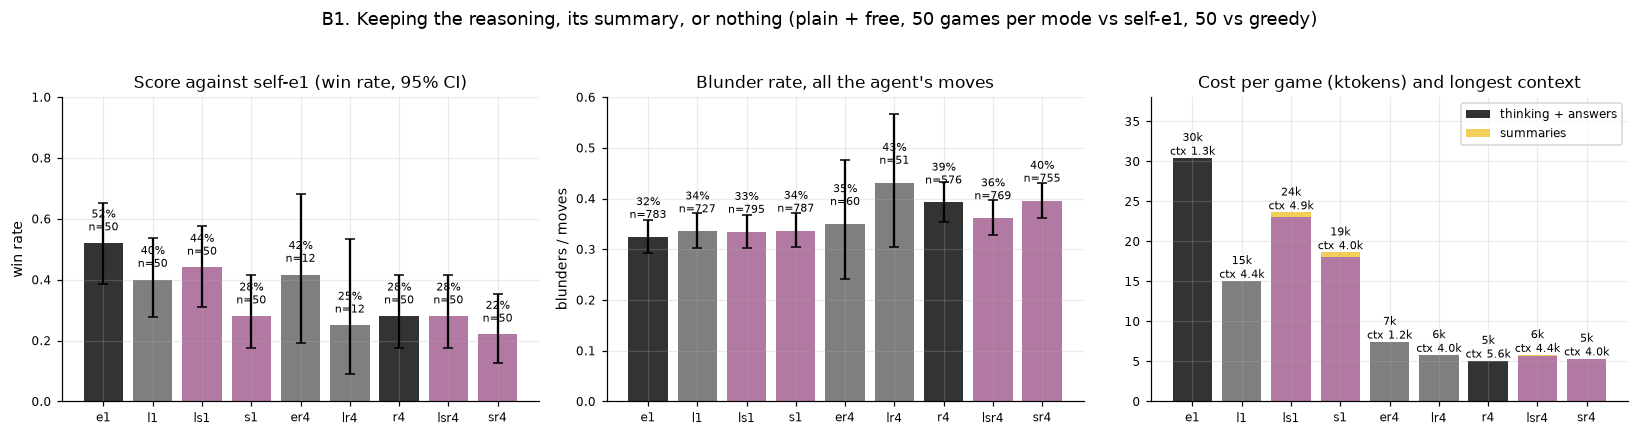

In [9]:
order_B1 = ["e1", "l1", "ls1", "s1"]; order_B4 = ["er4", "lr4", "r4", "lsr4", "sr4"]
print("Against self-e1:"); display(game_table(B, "self-e1").reindex(order_B1 + order_B4).round(2))
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
t = B[B.level == "self-e1"].groupby("mode").win.apply(rate).unstack().reindex(order_B1 + order_B4)
bars(axes[0], t, "p", "Score against self-e1 (win rate, 95% CI)", "win rate", palette(t.index))
t = move_rates(Bm, order=order_B1 + order_B4)
bars(axes[1], t, "p", "Blunder rate, all the agent's moves", "blunders / moves", palette(t.index), ylim=(0, 0.6))
g = B.groupby("mode").agg(ktok=("tokens_generated", lambda s: s.mean() / 1000), summ=("tokens_generated_summary", lambda s: s.fillna(0).mean() / 1000),
                          prompt=("tokens_max_prompt", "mean")).reindex(order_B1 + order_B4)
x = np.arange(len(g)); axes[2].bar(x, g.ktok - g.summ, color=palette(g.index), label="thinking + answers"); axes[2].bar(x, g.summ, bottom=g.ktok - g.summ, color="#F2CF5B", label="summaries")
for i, (k, pr) in enumerate(zip(g.ktok, g.prompt)): axes[2].text(i, k + 0.4, f"{k:.0f}k\nctx {pr/1000:.1f}k", ha="center", fontsize=7)
axes[2].set_xticks(x); axes[2].set_xticklabels(g.index); axes[2].set_title("Cost per game (ktokens) and longest context"); axes[2].legend(); axes[2].set_ylim(0, g.ktok.max() * 1.25)
fig.suptitle("B1. Keeping the reasoning, its summary, or nothing (plain + free, 50 games per mode vs self-e1, 50 vs greedy)", y=1.03)
plt.tight_layout(); plt.show()

In [10]:
Bs = B[B.level == "self-e1"]
pd.DataFrame([
    fisher(Bs[Bs["mode"] == "e1"].win, Bs[Bs["mode"] == "l1"].win, "e1", "l1", "win vs self-e1 (drop vs keep last)"),
    fisher(Bs[Bs["mode"] == "e1"].win, Bs[Bs["mode"] == "ls1"].win, "e1", "ls1", "win vs self-e1 (drop vs last summary)"),
    fisher(Bs[Bs["mode"] == "e1"].win, Bs[Bs["mode"] == "s1"].win, "e1", "s1", "win vs self-e1 (drop vs all summaries)"),
    fisher(Bs[Bs["mode"] == "ls1"].win, Bs[Bs["mode"] == "s1"].win, "ls1", "s1", "win vs self-e1 (last summary vs all)"),
    fisher(Bm[Bm.player_mode == "e1"].blunder, Bm[Bm.player_mode == "s1"].blunder, "e1", "s1", "blunder rate"),
    fisher(Bm[Bm.player_mode == "e1"].blunder, Bm[Bm.player_mode == "l1"].blunder, "e1", "l1", "blunder rate"),
    fisher(Bm[Bm.player_mode == "r4"].blunder, Bm[Bm.player_mode == "sr4"].blunder, "r4", "sr4", "blunder rate"),
    fisher(Bm[Bm.player_mode == "r4"].blunder, Bm[Bm.player_mode == "lsr4"].blunder, "r4", "lsr4", "blunder rate"),
]).round(3)

,what,a,rate_a,n_a,b,rate_b,n_b,p,verdict
0,win vs self-e1 (drop vs keep last),e1,0.52,50,l1,0.40,50,0.32,not distinguishable
1,win vs self-e1 (drop vs last summary),e1,0.52,50,ls1,0.44,50,0.55,not distinguishable
2,win vs self-e1 (drop vs all summaries),e1,0.52,50,s1,0.28,50,0.02,different (p<0.05)
3,win vs self-e1 (last summary vs all),ls1,0.44,50,s1,0.28,50,0.14,not distinguishable
4,blunder rate,e1,0.32,783,s1,0.34,787,0.63,not distinguishable
5,blunder rate,e1,0.32,783,l1,0.34,727,0.66,not distinguishable
6,blunder rate,r4,0.39,576,sr4,0.40,755,0.91,not distinguishable
7,blunder rate,r4,0.39,576,lsr4,0.36,769,0.26,not distinguishable


In [11]:
# the same picture at the move level: blunder rates on critical and quiet positions do not move with the memory
ms = ga.mode_summary(Bm, "player_mode").reindex(order_B1 + order_B4)
ms[["moves", "think_pct", "blunder_pct", "blunder_critical_pct", "blunder_quiet_pct", "blunder_thought_pct", "blunder_fast_pct"]]

,moves,think_pct,blunder_pct,blunder_critical_pct,blunder_quiet_pct,blunder_thought_pct,blunder_fast_pct
player_mode,,,,,,,
e1,783,87.7,32.4,80.0,16.7,29.1,56.2
l1,727,86.8,33.6,80.5,16.9,30.1,56.2
ls1,795,87.4,33.5,80.4,15.6,30.2,56.0
s1,787,87.3,33.7,81.7,15.9,30.4,56.0
er4,60,20.0,35.0,100.0,15.2,16.7,39.6
lr4,51,21.6,43.1,89.5,15.6,36.4,45.0
r4,576,17.9,39.2,85.5,20.7,35.9,40.0
lsr4,769,17.6,36.2,89.3,17.8,37.0,36.0
sr4,755,16.6,39.6,88.9,18.7,40.0,39.5


In [12]:
# does the model think longer or get cut off more when its notes are in the context? (capped: the reasoning hit the 10k-token limit)
B.groupby("mode").agg(games=("seed", "size"), think_turns=("tokens_think_turns", "mean"), capped_think=("tokens_capped_think_turns", "mean"),
                       ktok_thinking=("tokens_generated_thinking", lambda s: s.mean() / 1000), illegal=("illegal", "mean"),
                       plies=("plies", "mean")).reindex(order_B1 + order_B4).round(2)

,games,think_turns,capped_think,ktok_thinking,illegal,plies
mode,,,,,,
e1,100,7.21,0.13,30.42,0.15,16.33
l1,100,6.71,0.08,15.04,0.13,15.43
ls1,100,7.10,0.13,23.07,0.15,16.15
s1,100,7.22,0.35,18.10,0.35,16.06
er4,12,1.50,0.08,7.41,0.17,16.00
lr4,12,1.25,0.00,5.76,0.00,13.42
r4,80,1.35,0.01,5.04,0.18,15.52
lsr4,100,1.35,0.02,5.65,0.07,15.70
sr4,100,1.25,0.01,5.21,0.05,15.46


**Verdict B.** *Found nothing that helps:* at the move level the four memories of `e1` / `l1` / `ls1` / `s1` have the same blunder rate
(32-34%), the same blunder rate on critical positions (80-82%), and the same repair rate; the every-4 group is equally flat.
On score, keeping *all* the notes (`s1`) is worse than dropping everything (`e1`) against self-e1, and the summaries cost about 500 extra tokens
per game; `ls1` and `l1` sit in between and are not distinguishable from `e1`. Together with the earlier memory grid, this is the third
time the memory of the reasoning fails to change the play: the thinking frequency matters, what stays in the context does not, and compressing
instead of keeping does not rescue it. The one new fact is that *more* memory (every note) is, if anything, harmful: the model with its own notes
in front of it blunders as often and wins less.

## C. The surprise: think when the opponent did something unexpected

With the `predict` prompt every answer names the column the model expects the other player to play next ("4 (expecting 3)"). `gsurp` thinks
when that expectation fails, or when the model gave none; a second no-think context of the same model extracts the expectation from what the
agent wrote. `e1`, `r4`, `gcrit` and `grand35` play with the same prompt, so their predictions are measured too.

Against self-e1:


,games,score,win,lo,hi,think_rate,blunders_per_game,ktokens,illegal_per_game
r4,25.0,0.32,0.32,0.17,0.52,0.19,3.20,5.18,0.04
gcrit,25.0,0.40,0.40,0.23,0.59,0.33,2.80,7.34,0.12
grand35,25.0,0.60,0.60,0.41,0.77,0.39,1.88,9.39,0.16
gsurp,25.0,0.36,0.36,0.20,0.55,0.69,2.08,18.72,0.12
e1,25.0,0.48,0.48,0.30,0.67,0.86,2.28,25.86,0.20


Against greedy:


,games,score,win,lo,hi,think_rate,blunders_per_game,ktokens,illegal_per_game
r4,25.0,0.00,0.00,0.00,0.13,0.19,2.76,5.73,0.44
gcrit,25.0,0.02,0.00,0.00,0.13,0.24,2.32,6.21,1.28
grand35,25.0,0.06,0.04,0.01,0.20,0.35,2.60,11.55,0.08
gsurp,25.0,0.12,0.12,0.04,0.30,0.76,2.84,25.26,0.24
e1,25.0,0.04,0.04,0.01,0.20,0.87,2.60,30.37,0.12


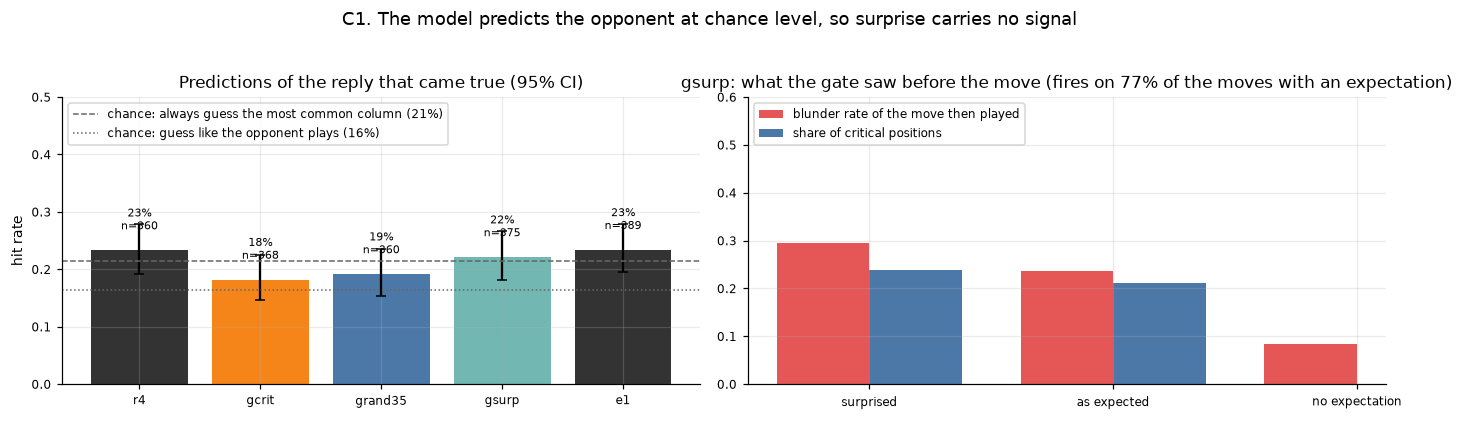

gsurp: extractor and regex reading of the answer agree on 81% of the moves; thinking rate 74%


In [13]:
order_C = ["r4", "gcrit", "grand35", "gsurp", "e1"]
print("Against self-e1:"); display(game_table(Cg, "self-e1").reindex(order_C).round(2))
print("Against greedy:"); display(game_table(Cg, "greedy").reindex(order_C).round(2))
# how good are the predictions? the chance level: guessing the most common reply, or drawing a reply from the reply distribution
replies = Cm.reply.dropna().value_counts(normalize=True)
chance_mode, chance_draw = replies.max(), (replies ** 2).sum()
hits = Cm[Cm.hit.notna()].groupby("player_mode").hit.apply(rate).unstack().reindex(order_C)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
bars(axes[0], hits, "p", "Predictions of the reply that came true (95% CI)", "hit rate", palette(order_C), ylim=(0, 0.5))
axes[0].axhline(chance_mode, ls="--", color="#666", lw=1, label=f"chance: always guess the most common column ({chance_mode:.0%})")
axes[0].axhline(chance_draw, ls=":", color="#666", lw=1, label=f"chance: guess like the opponent plays ({chance_draw:.0%})")
axes[0].legend(loc="upper left")
sq = ga.surprise_quality(Cm).loc["gsurp"]
cats = ["surprised", "as expected", "no expectation"]
vals = [sq.blunder_surprised_pct, sq.blunder_expected_pct, sq.blunder_no_expectation_pct]
crit = [sq.critical_when_surprised_pct, sq.critical_when_expected_pct, np.nan]
x = np.arange(3); w = 0.38
axes[1].bar(x - w/2, np.array(vals) / 100, w, color="#E45756", label="blunder rate of the move then played")
axes[1].bar(x + w/2, np.array(crit) / 100, w, color="#4C78A8", label="share of critical positions")
axes[1].set_xticks(x); axes[1].set_xticklabels([f"{c}\n" for c in cats]); axes[1].set_ylim(0, 0.6); axes[1].legend()
axes[1].set_title(f"gsurp: what the gate saw before the move (fires on {sq.surprised_pct:.0f}% of the moves with an expectation)")
fig.suptitle("C1. The model predicts the opponent at chance level, so surprise carries no signal", y=1.03)
plt.tight_layout(); plt.show()
print(f"gsurp: extractor and regex reading of the answer agree on {sq.agree_pct:.0f}% of the moves; thinking rate {Cm[Cm.player_mode=='gsurp'].think.mean():.0%}")

In [14]:
# if any mode had used surprise as its gate: is the move after a missed prediction more often a blunder, or a critical position?
rows = []
for (mode, level, seed), g in Cm.groupby(["player_mode", "level", "seed"]):
    g = g.sort_values("ply"); prev = g.hit.shift(1)
    for h, bl, cr in zip(prev, g.blunder, g.critical):
        if h is None or (isinstance(h, float) and np.isnan(h)): continue
        rows.append(dict(mode=mode, after=("reply as expected" if h else "reply unexpected"), blunder=bl, critical=cr))
after = pd.DataFrame(rows)
summary = after.groupby(["mode", "after"]).agg(moves=("blunder", "size"), blunder_rate=("blunder", "mean"), critical_share=("critical", "mean")).round(2)
display(summary.unstack("after"))
pd.DataFrame([fisher(after[after.after == "reply unexpected"].blunder, after[after.after == "reply as expected"].blunder, "unexpected", "expected", "blunder rate of the next move, all modes"),
              fisher(after[after.after == "reply unexpected"].critical, after[after.after == "reply as expected"].critical, "unexpected", "expected", "critical share of the next position, all modes")]).round(3)

moves                       blunder_rate                     critical_share                 
after   reply as expected reply unexpected reply as expected reply unexpected reply as expected reply unexpected
mode                                                                                                            
e1                     83              269              0.19             0.29              0.18             0.23
gcrit                  53              276              0.40             0.38              0.15             0.22
grand35                61              265              0.28             0.29              0.08             0.20
gsurp                  76              261              0.24             0.30              0.21             0.24
r4                     70              248              0.33             0.39              0.21             0.27

,what,a,rate_a,n_a,b,rate_b,n_b,p,verdict
0,"blunder rate of the next move, all modes",unexpected,0.33,1319,expected,0.28,343,0.08,not distinguishable
1,"critical share of the next position, all modes",unexpected,0.23,1319,expected,0.17,343,0.02,different (p<0.05)


**Verdict C.** *Found nothing, and we know why:* the model's expectations of the opponent's reply come true 18-23% of the time, which is the
chance level (the most common column is played 21% of the time). A gate built on them fires on three moves out of four, so `gsurp` is `e1` with
a few moves skipped: same blunder rate, same score, 25% fewer tokens. There is a faint signal: the position after a missed prediction is critical
23% of the time against 17% after a correct one (p=0.02), and the next move is a blunder 33% against 28% (p=0.08). But with four replies out of
five "unexpected", a gate on it cannot be selective. The design is sound (the extractor agrees with the literal reading of the answer on 81% of
the moves); the premise, that this model has a usable model of its opponent, is false for Qwen3-4B in Connect Four.

## D. Across the three experiments

Three things hold in every grid and are the results to take away.

Against the one-ply greedy bot, all modes and prompts: 22 wins in 635 games (3.5%); as first player 3.0%, as second 4.0%
All 10546 judged moves: 27% critical. Blunder rate: fast answer 86% on critical / 18% on quiet; thought answer 67% on critical / 17% on quiet


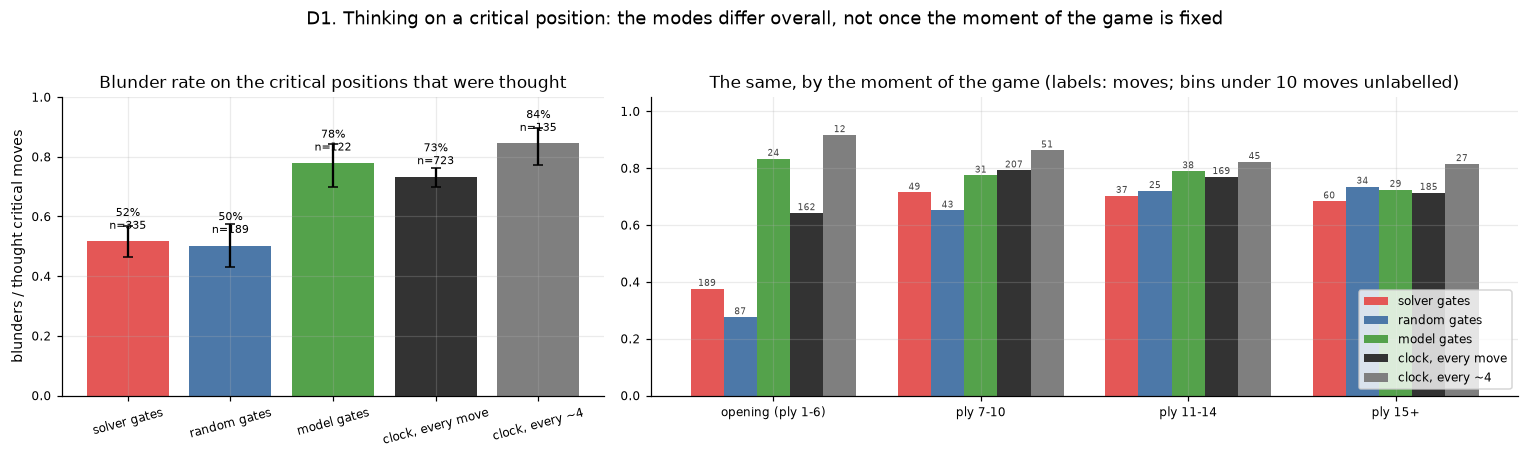

share of the thought critical moves,opening (ply 1-6),ply 7-10,ply 11-14,ply 15+
family,,,,
solver gates (goracle gcrit),0.56,0.15,0.11,0.18
random gates (grand28/35/42/55),0.46,0.23,0.13,0.18
model gates (gself gsurp),0.20,0.25,0.31,0.24
"clock, every move (e1 l1 s1 ls1)",0.22,0.29,0.23,0.26
"clock, every ~4 (r4 lr4 er4 sr4 lsr4)",0.09,0.38,0.33,0.20


,what,a,rate_a,n_a,b,rate_b,n_b,p,verdict
0,"blunder on thought critical moves, all modes",opening,0.48,474,ply 7+,0.75,1030,0.00,different (p<0.05)
1,"blunder on thought critical moves, ply 7+",solver gates,0.70,146,clock every move,0.76,561,0.14,not distinguishable
2,"blunder on thought critical moves, ply 7+",random gates,0.70,102,clock every move,0.76,561,0.17,not distinguishable


In [15]:
# 1. nobody beats the greedy bot
gr = games[games.level == "greedy"]
print(f"Against the one-ply greedy bot, all modes and prompts: {gr.win.sum()} wins in {len(gr)} games ({gr.win.mean():.1%}); "
      f"as first player {gr[gr.color=='X'].win.mean():.1%}, as second {gr[gr.color=='O'].win.mean():.1%}")
# 2. critical positions: the fast answer is almost always wrong, and thinking repairs under half of them
allm = own[own.level.isin(['greedy', 'self-e1'])]
fast_crit = allm[allm.critical & ~allm.think].blunder.mean(); fast_quiet = allm[~allm.critical & ~allm.think].blunder.mean()
th_crit = allm[allm.critical & allm.think].blunder.mean(); th_quiet = allm[~allm.critical & allm.think].blunder.mean()
print(f"All {len(allm)} judged moves: {allm.critical.mean():.0%} critical. Blunder rate: fast answer {fast_crit:.0%} on critical / {fast_quiet:.0%} on quiet; "
      f"thought answer {th_crit:.0%} on critical / {th_quiet:.0%} on quiet")
# 3. the thought bars of A2 differed a lot between modes: by ply, they do not
th = own[own.critical & own.think & own.level.isin(['greedy', 'self-e1'])].copy()
FAM = {"e1": "clock, every move (e1 l1 s1 ls1)", "l1": "clock, every move (e1 l1 s1 ls1)", "s1": "clock, every move (e1 l1 s1 ls1)", "ls1": "clock, every move (e1 l1 s1 ls1)",
       "r4": "clock, every ~4 (r4 lr4 er4 sr4 lsr4)", "lr4": "clock, every ~4 (r4 lr4 er4 sr4 lsr4)", "er4": "clock, every ~4 (r4 lr4 er4 sr4 lsr4)", "sr4": "clock, every ~4 (r4 lr4 er4 sr4 lsr4)", "lsr4": "clock, every ~4 (r4 lr4 er4 sr4 lsr4)",
       "goracle": "solver gates (goracle gcrit)", "gcrit": "solver gates (goracle gcrit)",
       "grand28": "random gates (grand28/35/42/55)", "grand35": "random gates (grand28/35/42/55)", "grand42": "random gates (grand28/35/42/55)", "grand55": "random gates (grand28/35/42/55)",
       "gself": "model gates (gself gsurp)", "gsurp": "model gates (gself gsurp)"}
th["family"] = th.player_mode.map(FAM)
th["phase"] = pd.cut(th.ply, [0, 6, 10, 14, 50], labels=["opening (ply 1-6)", "ply 7-10", "ply 11-14", "ply 15+"])
fam_order = ["solver gates (goracle gcrit)", "random gates (grand28/35/42/55)", "model gates (gself gsurp)", "clock, every move (e1 l1 s1 ls1)", "clock, every ~4 (r4 lr4 er4 sr4 lsr4)"]
overall = th.groupby("family").blunder.apply(rate).unstack().reindex(fam_order)
byphase = th.groupby(["family", "phase"], observed=True).blunder.agg(["size", "mean"]).unstack("phase")
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1, 1.6]})
bars(axes[0], overall, "p", "Blunder rate on the critical positions that were thought", "blunders / thought critical moves",
     ["#E45756", "#4C78A8", "#54A24B", "#333333", "#7F7F7F"])
axes[0].set_xticklabels([f.split(" (")[0] for f in fam_order], rotation=15)
phases = list(byphase["mean"].columns); x = np.arange(len(phases)); w = 0.16
for i, (fam, col) in enumerate(zip(fam_order, ["#E45756", "#4C78A8", "#54A24B", "#333333", "#7F7F7F"])):
    means = byphase["mean"].reindex([fam]).iloc[0]; ns = byphase["size"].reindex([fam]).iloc[0]
    axes[1].bar(x + (i - 2) * w, means, w, color=col, label=fam.split(" (")[0])
    for xi, (mv, nv) in enumerate(zip(means, ns)):
        if nv == nv and nv >= 10: axes[1].text(xi + (i - 2) * w, mv + 0.01, f"{int(nv)}", ha="center", fontsize=6, color="#444")
axes[1].set_xticks(x); axes[1].set_xticklabels(phases); axes[1].set_ylim(0, 1.05); axes[1].legend(loc="lower right")
axes[1].set_title("The same, by the moment of the game (labels: moves; bins under 10 moves unlabelled)")
fig.suptitle("D1. Thinking on a critical position: the modes differ overall, not once the moment of the game is fixed", y=1.03)
plt.tight_layout(); plt.show()
share = th.groupby("family").phase.value_counts(normalize=True).unstack().reindex(fam_order).round(2)
share.columns.name = "share of the thought critical moves"; display(share)
op = th[th.phase == "opening (ply 1-6)"]; late = th[th.phase != "opening (ply 1-6)"]
pd.DataFrame([fisher(op.blunder, late.blunder, "opening", "ply 7+", "blunder on thought critical moves, all modes"),
              fisher(late[late.family.str.startswith("solver")].blunder, late[late.family.str.startswith("clock, every move")].blunder, "solver gates", "clock every move", "blunder on thought critical moves, ply 7+"),
              fisher(late[late.family.str.startswith("random")].blunder, late[late.family.str.startswith("clock, every move")].blunder, "random gates", "clock every move", "blunder on thought critical moves, ply 7+")]).round(3)

**Verdict D.**
1. **The greedy bot is unbeaten** in more than 600 games whatever the thinking schedule or memory: Qwen3-4B's reasoning does not reach one ply of
   lookahead in Connect Four. The self-play scores measure relative strength only.
2. **Blunders live on the critical quarter of the positions.** There the fast answer is wrong ~85% of the time and thinking brings it to ~65%;
   on quiet positions the fast answer is fine ~80% of the time and thinking adds nothing measurable. Any "when to think" policy is a
   critical-position detector, and the model is not one (`gself`, the surprise).
3. **Thinking works in the opening and fails later, in every mode.** In the first six plies "critical" means "only the centre keeps the win", and a
   thought move gets it right about half the time (the gates two times out of three); from ply 7 on, where critical means a threat to see and
   block, a thought move is a blunder 70-80% of the time in every family of modes (p=0.14 and 0.17 between the gates and `e1`'s family). The gate modes looked better at thinking on critical positions in A2 only because they think early
   (the solver sends `gcrit` to every opening position) and the clock modes meet their critical positions later. So the ceiling of any gate is
   set by this: when the position is hard, this model's reasoning fails three times out of four, whoever decides that it should reason.